In [18]:
%load_ext autoreload
%autoreload 2
import sys
sys.path.append('..')
from src.data_loading import load_data, split_train_test_freq
from src.features import preparer, modalites_frequentes, regrouper, matrice_design
from src.graph import plot_freq_par_groupe, freq_par_groupe
from src.metrics import comparer_tranches
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm


freq, sev = load_data()
train, test = split_train_test_freq(freq, test_size=0.2, random_state=42)

for nom, table in [("train", train), ("test", test)]:
    print(f"Exposition totale de {nom} : ", table["Exposure"].sum().round(3))
    print(f"ClaimNb totale de {nom} : ", table["ClaimNb"].sum())
    print(f"Fréquence annualisée de {nom} : ", (table["ClaimNb"].sum() / table["Exposure"].sum()).round(5))

print("Proportion de l'exposition dans le test : ", (test["ClaimNb"].sum() / (test["ClaimNb"].sum()+train["ClaimNb"].sum())).round(4))

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Exposition totale de train :  286776.503
ClaimNb totale de train :  28831
Fréquence annualisée de train :  0.10053
Exposition totale de test :  71583.603
ClaimNb totale de test :  7225
Fréquence annualisée de test :  0.10093
Proportion de l'exposition dans le test :  0.2004


`Exposition` : Même si le split porte sur le nombre de police et non sur l'exposition, le fait que par coïncidence 20% de l'exposition soit sur le jeu de test confirme qu'il n'y a pas de biais entre exposition et probabilité d'être tiré.

`Fréquences` : 0.10053 et 0.10093 cont 0.1005 sur le portefeuille complet. L'écart entre les deux est de 0.4%. Sachant que le test contient 7225 sinistres, l'incertitude relative (mesure suivant une statistique de poisson) sur sa fréquence est de `1/√7224 ≈ 1,2 %`. L'écart observé est environ 3 fois plus petit donc rien à signaler.

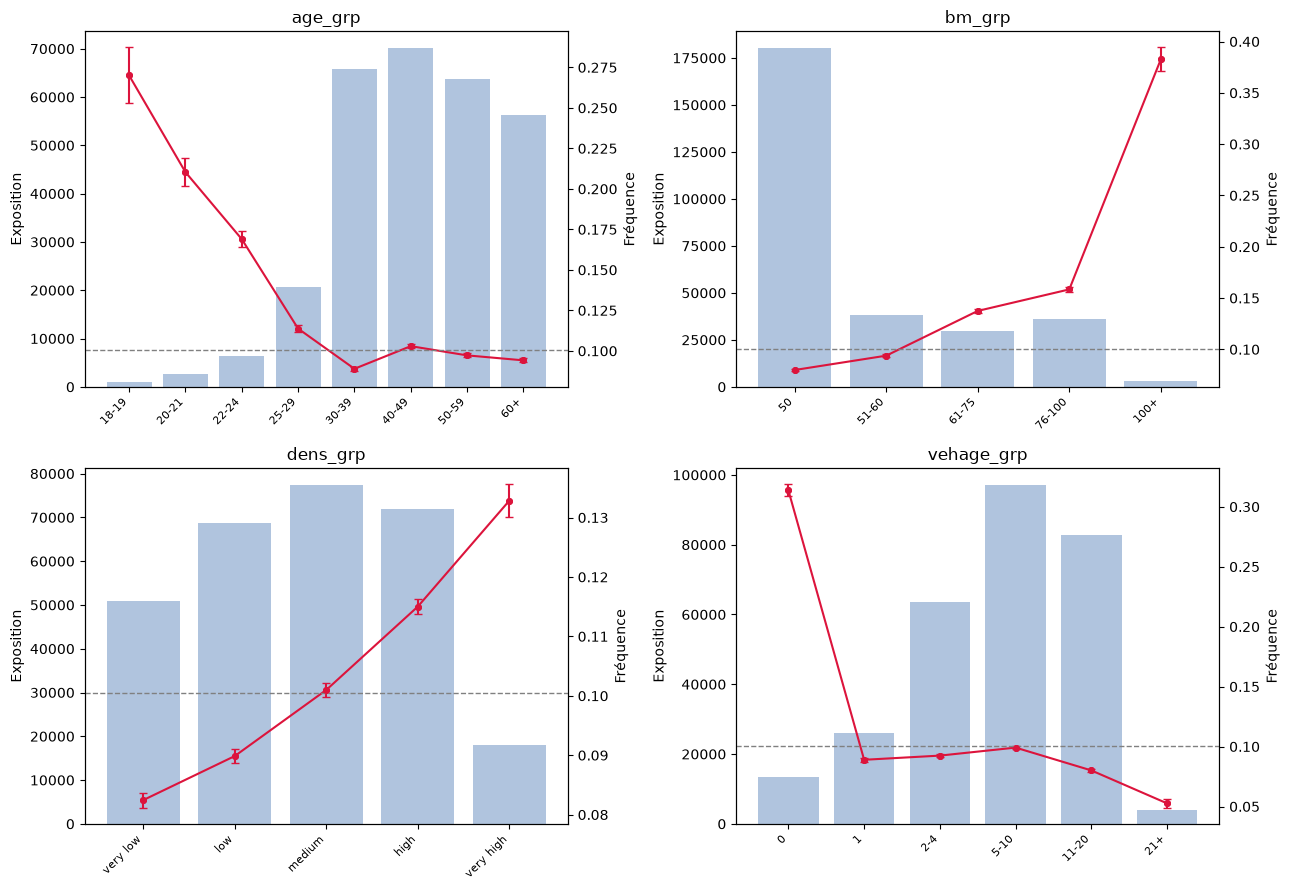

In [8]:
train_prep = preparer(train, decoupage="grossier")
test_prep  = preparer(test, decoupage="grossier")

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, col in zip(axes.flat, ["age_grp", "bm_grp", "dens_grp", "vehage_grp"]):
    plot_freq_par_groupe(train_prep, col, ax=ax, errorbar=True)
plt.tight_layout()


Pour les variables de catégorie, nous regroupons celles qui ont une exposition trop faible ( < 5000 ) car elles présenteraient une erreur relative trop importante sur la fréquence (pour 800 années-police -> environ 80 sinitres et une erreur relative de 11%).

In [9]:
modalites = {}

ETIQUETTE_AUTRE = {"VehPower": "12+", "Region": "Autres", "VehBrand": "Autres"}

for col in ["Region", "VehBrand", "VehPower"]:
    modalites[col] = modalites_frequentes(train_prep, col)
    train_prep = regrouper(train_prep, col, modalites[col], autre=ETIQUETTE_AUTRE[col])
    test_prep  = regrouper(test_prep,  col, modalites[col], autre=ETIQUETTE_AUTRE[col])


Nous allons regarder si certaines partie du découpages des variables `age_grp`, `bm_grp`, `dens_grp` et `vehage_grp` peuvent être fusionnées si elles ont un faible écart de fréquence et de petites erreurs relatives.

La statistique derrière cette fonction : l'écart type relatif du comptage vaut 1/√N (N = nombre de sinistres). Pour l'écart type de la fréquence, on divise par l'exposition qui est considérée comme une valeur connue et on obtient σ(f) = √N / exposition = f / √N.
Pour l'écart entre deux tranches, la variance d'une différence de deux variables aléatoires indépendantes est la somme des variances. Ainsi, le rapport |f₁ − f₂| / σ_écart compte l'écart en nombre d'écarts types ce qui permet de savoir réellement si l'écart observé est important.

In [10]:

for col in ["age_grp", "bm_grp", "dens_grp", "vehage_grp"]:
    print(f"\n === {col} === \n")
    print(comparer_tranches(train_prep, col))


 === age_grp === 

           paire     ecart  sigma_ecart   rapport
0  18-19 / 20-21  0.059678     0.019400  3.076198
1  20-21 / 22-24  0.041363     0.010237  4.040661
2  22-24 / 25-29  0.055220     0.005619  9.827525
3  25-29 / 30-39  0.024822     0.002620  9.473779
4  30-39 / 40-49  0.013979     0.001679  8.327129
5  40-49 / 50-59  0.005692     0.001730  3.291147
6    50-59 / 60+  0.003066     0.001788  1.714732

 === bm_grp === 

            paire     ecart  sigma_ecart    rapport
0      50 / 51-60  0.013968     0.001700   8.215515
1   51-60 / 61-75  0.043610     0.002664  16.369814
2  61-75 / 76-100  0.020974     0.003011   6.965382
3   76-100 / 100+  0.224172     0.011762  19.058303

 === dens_grp === 

              paire     ecart  sigma_ecart   rapport
0    very low / low  0.007413     0.001711  4.332397
1      low / medium  0.011127     0.001616  6.883772
2     medium / high  0.014026     0.001704  8.229313
3  high / very high  0.017828     0.003003  5.936061

 === vehage_gr

Pour `age_grp`, les fréquences de `60-69` (0.0934) et `70+` (0.0952) ne diffèrent que de 0.0012 pour un rapport de différence par rapport à l'écart-type de 0.68 . La distinction des deux catégorie n'est pas justifiée par les données observée, on peut donc les fusionner en `60+`.



Deux autres paires restent en zone grise et seront testé par AIC : 
- `age_grp` : `50-59` et `60+` (rapport 1.9)  
- `vehage_grp` : `1` et `2-4` (rapport 1.6)

In [11]:
X_train = matrice_design(train_prep)
print(X_train.shape)
print(X_train.columns.tolist())

(542410, 53)
['const', 'age_grp_18-19', 'age_grp_20-21', 'age_grp_22-24', 'age_grp_25-29', 'age_grp_40-49', 'age_grp_50-59', 'age_grp_60+', 'bm_grp_51-60', 'bm_grp_61-75', 'bm_grp_76-100', 'bm_grp_100+', 'vehage_grp_0', 'vehage_grp_1', 'vehage_grp_2-4', 'vehage_grp_11-20', 'vehage_grp_21+', 'dens_grp_very low', 'dens_grp_low', 'dens_grp_high', 'dens_grp_very high', 'VehGas_Diesel', 'VehPower_10', 'VehPower_11', 'VehPower_12+', 'VehPower_4', 'VehPower_5', 'VehPower_7', 'VehPower_8', 'VehPower_9', 'VehBrand_Autres', 'VehBrand_B1', 'VehBrand_B10', 'VehBrand_B11', 'VehBrand_B13', 'VehBrand_B2', 'VehBrand_B3', 'VehBrand_B4', 'VehBrand_B5', 'VehBrand_B6', 'Region_Autres', 'Region_R11', 'Region_R25', 'Region_R31', 'Region_R41', 'Region_R52', 'Region_R53', 'Region_R54', 'Region_R72', 'Region_R73', 'Region_R82', 'Region_R91', 'Region_R93']


In [12]:
y_train = train_prep["ClaimNb"]
offset_train = np.log(train_prep["Exposure"])


glm_freq = sm.GLM(y_train, X_train, family=sm.families.Poisson(), offset=offset_train).fit()

print(glm_freq.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                ClaimNb   No. Observations:               542410
Model:                            GLM   Df Residuals:                   542357
Model Family:                 Poisson   Df Model:                           52
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:            -1.1269e+05
Date:                Sat, 12 Sep 2026   Deviance:                   1.6993e+05
Time:                        20:50:07   Pearson chi2:                 1.25e+06
No. Iterations:                     7   Pseudo R-squ. (CS):            0.01705
Covariance Type:            nonrobust                                         
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                 -2.5432      0

In [34]:
mu = glm_freq.predict(X_train, offset=offset_train)
print("Somme des prédictions : ", mu.sum().round(1))
print("Somme des sinistres observés : ", y_train.sum())

Somme des prédictions :  28831.0
Somme des sinistres observés :  28831


### Spécification

Poisson à lien logarithmique, exposition en offset :

`log(E[ClaimNb]) = log(Exposure) + β′x`

L'offset entre avec un coefficient contraint à 1, de sorte que `exp(β′x)` s'interprète directement comme la fréquence annualisée.

53 paramètres estimés sur 542 410 polices.

Convergence de l'IRLS en 7 itérations.
Somme des prédictions égale à la somme des sinistres observés (propriété du lien canonique avec constante).
Aucune erreur standard aberrante : pas de colinéarité résiduelle après regroupement des modalités rares.

In [23]:
res = pd.DataFrame({"coef": glm_freq.params,"facteur": np.exp(glm_freq.params),"std_err": glm_freq.bse, "z": glm_freq.tvalues,}).round(4)
print(res)

                      coef  facteur  std_err        z
const              -2.5432   0.0786   0.0327 -77.8436
age_grp_18-19       0.7591   2.1364   0.0664  11.4275
age_grp_20-21       0.4121   1.5100   0.0460   8.9622
age_grp_22-24       0.1551   1.1677   0.0347   4.4686
age_grp_25-29      -0.0848   0.9187   0.0251  -3.3742
age_grp_40-49       0.3537   1.4244   0.0183  19.3748
age_grp_50-59       0.3385   1.4029   0.0193  17.5579
age_grp_60+         0.3346   1.3973   0.0204  16.3944
bm_grp_51-60        0.2917   1.3388   0.0195  14.9495
bm_grp_61-75        0.6935   2.0007   0.0191  36.3481
bm_grp_76-100       0.8237   2.2788   0.0192  42.9943
bm_grp_100+         1.7050   5.5011   0.0337  50.6429
vehage_grp_0        1.1365   3.1158   0.0206  55.2319
vehage_grp_1       -0.1208   0.8862   0.0244  -4.9428
vehage_grp_2-4     -0.0590   0.9427   0.0172  -3.4338
vehage_grp_11-20   -0.2241   0.7993   0.0163 -13.7673
vehage_grp_21+     -0.5406   0.5824   0.0692  -7.8129
dens_grp_very low  -0.1168  

### Grille tarifaire estimée

Profil de référence : conducteur de 30-39 ans, bonus 50, densité moyenne, véhicule essence de 5-10 ans, puissance 6, marque B12, région R24. Fréquence prédite : 0,0786.

#### L'effet de l'âge est grandement modifié par le contrôle.
| ranche | Fréquence brute | Effet marginal |	Effet GLM |
|---|---|---|---|
|18-19|0,2700|×3,04|×2,14|
|20-21|	0,2104|	×2,37|	×1,51|
|22-24|0,1690|	×1,90|×1,17|
|25-29|	 0,1138|  ×1,28|	×0,92|
|30-39|	0,0889|	×1,00|	×1,00|
|40-49|0,1029|×1,16|	×1,42|
|50-59|0,0972|	×1,09|	×1,40|
|60+|	0,0940|	 ×1,06|	×1,40|

Observations : 

- Les jeunes sont attenués d'un tier. Le facteur 3.04 observé chez les `18-19` passe à 2.14 une fois les autres variables contrôlées.

- La tranche 25-29 change de signe. Supérieur de 28 % en brut, elle est inférieur de 8 % à profil comparable.

- Les 40+ sont amplifiés, de ×1,10 environ à ×1,40.

#### Autres variables :

- `Bonus-malus` : la variable dominante : ×1,34 (51-60), ×2,00 (61-75), ×2,28 (76-100), ×5,50 (100+). Strictement monotone, tous les coefficients au-delà de 14 σ montrent que cette variable est très significative dans la tarification.

- `Âge du véhicule` : le véhicule de moins d'un an ressort à ×3,12, contre ×3,17 en marginal : l'effet est pratiquement inchangé par le contrôle, donc indépendante aux autres variables. L'interprétation reste ouverte : déclaration systématique des dommages légers sur un véhicule neuf, relation contractuelle récente... Les données ne permettent pas de trancher.

- `Densité` : fortement atténuée : l'amplitude passe de 1 à 1,61 en marginal à 1 à 1,22 après contrôle.

- `Puissance, marque, région` — effets faibles et, pour la puissance, non monotones. Pl




|Question|	Raisonnement |
|---|---|
|Fusionner 40-49, 50-59 et 60+ en 40+|	Les coefficients des trois tranches au-delà de 40 ans valent 0,354, 0,339 et 0,335, pour des erreurs standards de l'ordre de 0,019. L'écart entre les extrêmes est de 0,019, soit 0,7 fois son propre écart-type : les trois tranches ne sont pas distinguables une fois les autres variables contrôlées.|
|Fusionner high et very high|	Écart de 0,012 pour un écart-type combiné de 0,032 soit 0,4 fois l'écart type.|
|Conserver VehPower ?|	Non monotone : ×0,76 en puissance 8, ×1,07 en 9, soit un saut de 41 % entre deux modalités contiguës — indéfendable dans une grille. Trois modalités non significatives. À tester en bloc par déviance.|
|Interaction age_grp × dens_grp|	Question ouverte depuis la phase 0 (ratios non constants de zone en zone).|



In [27]:
mask = (
    (train_prep["age_grp"] == "30-39") & (train_prep["bm_grp"] == "50")
    & (train_prep["dens_grp"] == "medium") & (train_prep["vehage_grp"] == "5-10")
    & (train_prep["VehGas"] == "Regular") & (train_prep["VehPower"] == "6")
    & (train_prep["VehBrand"] == "B12") & (train_prep["Region"] == "R24")
)
sous = train_prep[mask]
print(sous)
#print(len(sous), sous["Exposure"].sum(), sous["ClaimNb"].sum() / sous["Exposure"].sum())

Empty DataFrame
Columns: [IDpol, ClaimNb, Exposure, Area, VehPower, VehAge, DrivAge, BonusMalus, VehBrand, VehGas, Density, Region, age_grp, bm_grp, log_Density, dens_grp, vehage_grp]
Index: []


Je voulais vérifier que la fréquence annualisé d'un assuré présentant les caractéristiques de références était la même que celle prédite par le modèle mais aucun assuré ne les cummule toutes.

Cela n'invalide en rien les résultats, en effet certaines des caractéristiques de référence étaient en proportion faible dans le portefeuille, toutes cumulées, cela devient très rare.

Nous allons donc relâcher les contraintes faibles et garder les plus dominantes.

In [32]:
mask = (
    (train_prep["age_grp"] == "30-39")
    & (train_prep["bm_grp"] == "50")
    & (train_prep["vehage_grp"] == "5-10")
)
sous = train_prep[mask]
#print(sous)

print(len(sous), sous["Exposure"].sum().round(0),
      (sous["ClaimNb"].sum() / sous["Exposure"].sum()).round(4))

print(mu[mask].sum() / sous["Exposure"].sum())

14883 9470.0 0.0518
0.05793332001966051
